# tcspc_lifetime — calibration and batch fit, end to end

This notebook drives the library the way the GUI will:

1. **Calibrate:** read the N repetitions of the calibration dye and extract the IRF from them.
2. **Read the samples.**
3. **Choose the model:** number of components, which parameters are free, their ranges, and the fitting interval.
4. **Fit every sample**, and plot each fit with its residuals.
5. **Distribution of each free parameter** across the samples, with its mean and spread.

It runs on the simulated example data in `data/`, whose true values are known (see `data/README.md`). To use your own measurements, change the file paths in sections 1 and 2.

The library computes and never draws; every plot here is made in this notebook, as the GUI will.

In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

import tcspc_lifetime
from tcspc_lifetime import Model, Parameter, read_decay, build_calibration, run_batch, SampleResult

print("tcspc_lifetime", tcspc_lifetime.__version__)

tcspc_lifetime 0.4.0


## 1 · Calibration

The calibration dye must be monoexponential, and measured in the same detection channel and filter range, with the same TCSPC settings, as the samples. Before summing the repetitions, the library checks that each one has the same shape as the others (a blind, model-free test). A repetition that fails is a different sample and is excluded; the rest are then re-tested among themselves.

The IRF is extracted from the sum. Its smoothing λ and cut m are chosen by **leaving one repetition out**: each candidate IRF is built from the other repetitions and scored on the one it never saw. The library also keeps the **leave-one-out IRFs**, which later measure how much each sample's result depends on the calibration's own noise.

In [2]:
# --- settings: your calibration files ---
CALIBRATION_FILES = sorted(Path("data/calibration").glob("*.csv"))
TIME_UNIT = "ns"                      # unit of the time column in the files: "ns" or "ps"

calibration_decays = [read_decay(path, time_unit=TIME_UNIT) for path in CALIBRATION_FILES]
for decay in calibration_decays:
    print(f"{decay.name}: {decay.counts.size} bins of {decay.bin_width_ns * 1000:.0f} ps, "
          f"peak {decay.counts.max():.0f} counts, total {decay.counts.sum():.3g}")

cal_01.csv: 250 bins of 100 ps, peak 10079 counts, total 2.46e+05
cal_02.csv: 250 bins of 100 ps, peak 10110 counts, total 2.46e+05
cal_03.csv: 250 bins of 100 ps, peak 10046 counts, total 2.47e+05
cal_04.csv: 250 bins of 100 ps, peak 10040 counts, total 2.81e+05
cal_05.csv: 250 bins of 100 ps, peak 10053 counts, total 2.46e+05


N = 5 repetitions; summed: ['cal_01.csv', 'cal_02.csv', 'cal_03.csv', 'cal_05.csv']
EXCLUDED cal_04.csv: shape test log10 p = -875 -> a different sample
shape-test p-values: {'cal_04.csv': '0', 'cal_01.csv': '0.29', 'cal_02.csv': '0.12', 'cal_03.csv': '0.79', 'cal_05.csv': '0.43'}
timing of each repetition (bins, vs median): {'cal_01.csv': '+0.08', 'cal_02.csv': '+0.07', 'cal_03.csv': '-0.07', 'cal_04.csv': '+2.61', 'cal_05.csv': '-0.25'}
IRF: λ = 0.04578 bins⁴, cut m = 23, 24 samples from 1.00 ns
λ and m chosen by: cross_validated; leave-one-out IRFs kept: 4
calibration dye lifetime (blind): 1.8695 ± 0.0020 ns


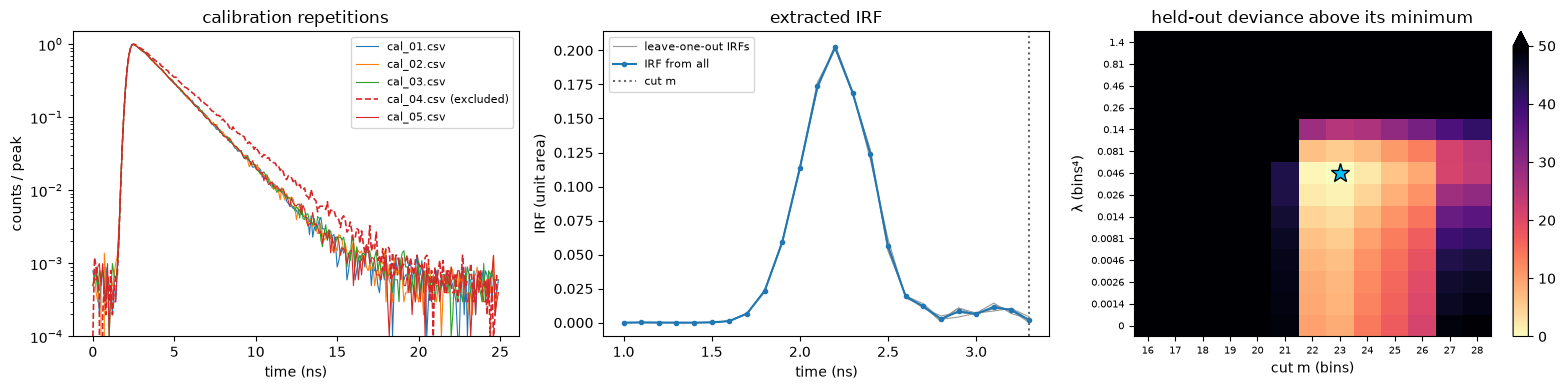

In [3]:
calibration = build_calibration(calibration_decays)

print(f"N = {calibration.n_repetitions} repetitions; summed: {calibration.accepted}")
for item in calibration.excluded:
    print(f"EXCLUDED {item['name']}: shape test log10 p = {item['log10_p_value']:.0f} -> a different sample")
print("shape-test p-values:", {name: f"{p:.2g}" for name, p in calibration.shape_test_p_values.items()})
print("timing of each repetition (bins, vs median):",
      {name: f"{offset:+.2f}" for name, offset in calibration.centroid_offsets_bins.items()})
print(f"IRF: λ = {calibration.best_lambda_bins4:.4g} bins⁴, cut m = {calibration.best_m_bin}, "
      f"{calibration.irf.size} samples from {calibration.time_ns[calibration.irf_start_bin]:.2f} ns")
print(f"λ and m chosen by: {calibration.selection}; leave-one-out IRFs kept: {len(calibration.jackknife_irfs)}")
print(f"calibration dye lifetime (blind): {calibration.tau_reference_ns:.4f} ± {calibration.tau_reference_error_ns:.4f} ns")

fig, (ax_reps, ax_irf, ax_score) = plt.subplots(1, 3, figsize=(16, 4))
excluded_names = [item["name"] for item in calibration.excluded]
for decay in calibration_decays:
    is_excluded = decay.name in excluded_names
    ax_reps.semilogy(decay.time_ns, decay.counts / decay.counts.max(), "--" if is_excluded else "-",
                     color="tab:red" if is_excluded else None, lw=1.2 if is_excluded else 0.8,
                     label=decay.name + (" (excluded)" if is_excluded else ""))
ax_reps.set(xlabel="time (ns)", ylabel="counts / peak", title="calibration repetitions", ylim=(1e-4, 1.5))
ax_reps.legend(fontsize=8)
irf_time = calibration.time_ns[calibration.irf_start_bin:calibration.irf_start_bin + calibration.irf.size]
for k, irf_k in enumerate(calibration.jackknife_irfs):
    ax_irf.plot(irf_time, irf_k, "-", lw=0.8, color="0.6", label="leave-one-out IRFs" if k == 0 else None)
ax_irf.plot(irf_time, calibration.irf, "o-", ms=3, color="tab:blue", label="IRF from all")
ax_irf.axvline(irf_time[-1], ls=":", color="0.4", label="cut m")
ax_irf.set(xlabel="time (ns)", ylabel="IRF (unit area)", title="extracted IRF")
ax_irf.legend(fontsize=8)
if calibration.selection_score_map is not None:
    score = calibration.selection_score_map - np.nanmin(calibration.selection_score_map)   # 0 at the chosen pair
    image = ax_score.pcolormesh(np.arange(calibration.m_grid_bin.size + 1) - 0.5,
                                np.arange(calibration.lambda_grid_bins4.size + 1) - 0.5,
                                np.minimum(score, 50), cmap="magma_r")
    i, j = np.unravel_index(np.argmin(score), score.shape)
    ax_score.plot(j, i, "*", ms=14, color="deepskyblue", markeredgecolor="k")
    ax_score.set_xticks(np.arange(calibration.m_grid_bin.size))
    ax_score.set_xticklabels([str(int(m)) for m in calibration.m_grid_bin], fontsize=7)
    ax_score.set_yticks(np.arange(calibration.lambda_grid_bins4.size))
    ax_score.set_yticklabels(["0"] + [f"{lam:.2g}" for lam in calibration.lambda_grid_bins4[1:]], fontsize=7)
    ax_score.set(xlabel="cut m (bins)", ylabel="λ (bins⁴)", title="held-out deviance above its minimum")
    fig.colorbar(image, ax=ax_score, extend="max")
plt.tight_layout()
plt.show()

calibration.save("calibration.json")           # reusable: Calibration.load("calibration.json")

## 2 · Samples

Same binning as the calibration (the library refuses anything else). The order of the files is taken as the acquisition order; the fitted shift then doubles as a drift monitor.

In [4]:
# --- settings: your sample files ---
SAMPLE_FILES = sorted(Path("data/samples").glob("*.csv"))

sample_decays = [read_decay(path, time_unit=TIME_UNIT) for path in SAMPLE_FILES]
print(f"{len(sample_decays)} samples: {sample_decays[0].name} ... {sample_decays[-1].name}")

12 samples: sample_01.csv ... sample_12.csv


## 3 · The model

Every option of the GUI's decay-parameter panel (modelled on SPCImage NG) is set here:

| Setting | Meaning |
|---|---|
| `n_components` | 1, 2 or 3 exponential components |
| `lifetimes_ns` | one `Parameter` per component: `value` (start, or the value if fixed), `fixed`, `lower`, `upper` in ns. Leave `value=None` to let a coarse search find the start. Giving each component its own range keeps the labels τ₁, τ₂ stable across samples. |
| `shift_bins` | IRF timing relative to the calibration, in bins (sub-bin). Default: free in [−3, 3]. |
| `scatter` | an IRF-shaped, instantaneous component (scattered excitation light), in counts. Default: fixed at 0. Kept ≥ 0 when free. |
| `offset` | flat background, counts per bin. Default: free. Kept ≥ 0. |
| `fit_start_ns`, `fit_end_ns` | fitting interval. The model is always computed over the whole histogram; only bins inside the interval enter the likelihood. `None` = from the calibration window's start to the end. |

Amplitudes are always free, as in SPCImage. Example: to fix τ₁ at a known value, use `Parameter(0.8, fixed=True)`.

In [5]:
# --- settings: the model ---
MODEL = Model(
    n_components=2,
    lifetimes_ns=[
        Parameter(value=None, fixed=False, lower=0.2, upper=1.8),    # τ1 (ns)
        Parameter(value=None, fixed=False, lower=1.8, upper=8.0),    # τ2 (ns)
    ],
    shift_bins=Parameter(value=0.0, fixed=False, lower=-3.0, upper=3.0),
    scatter=Parameter(value=0.0, fixed=True),
    offset=Parameter(value=None, fixed=False),
    fit_start_ns=1.0,
    fit_end_ns=20,
)
MODEL

Model(n_components=2, lifetimes_ns=[Parameter(value=None, fixed=False, lower=0.2, upper=1.8), Parameter(value=None, fixed=False, lower=1.8, upper=8.0)], shift_bins=Parameter(value=0.0, fixed=False, lower=-3.0, upper=3.0), scatter=Parameter(value=0.0, fixed=True, lower=None, upper=None), offset=Parameter(value=None, fixed=False, lower=None, upper=None), fit_start_ns=1.0, fit_end_ns=20)

## 4 · Fit every sample

Each sample is one Poisson maximum-likelihood fit. Every parameter gets three errors:

- **statistical:** the Fisher error from the sample's own photons;
- **IRF:** the jackknife error, from refitting the sample with each leave-one-out IRF — the calibration's photon noise, shared by every sample of the batch;
- **total:** the two combined, √(stat² + IRF²). The table shows value ± total.

In [6]:
def show_progress(done, total, name):
    print(f"\r{done}/{total} fitted ({name})", end="")

results = run_batch(sample_decays, calibration, MODEL, progress=show_progress)
fits = [r for r in results if isinstance(r, SampleResult)]
for failure in (r for r in results if not isinstance(r, SampleResult)):
    print(f"\nFAILED {failure.decay_name}: {failure.error_message}")
print()

LABELS = {"tau_1_ns": "τ1 (ns)", "tau_2_ns": "τ2 (ns)", "tau_3_ns": "τ3 (ns)",
          "amplitude_1_percent": "a1 (%)", "amplitude_2_percent": "a2 (%)", "amplitude_3_percent": "a3 (%)",
          "shift_bins": "shift (bins)", "scatter_counts": "scatter (counts)",
          "offset_counts_per_bin": "offset (counts/bin)", "tau_mean_intensity_ns": "τ intensity-weighted (ns)",
          "tau_mean_amplitude_ns": "τ amplitude-weighted (ns)"}
ALSO_SHOW = ["tau_mean_intensity_ns"]        # derived quantities to add to the table and the distributions


def shown_parameters(result):
    # the free fitted parameters; amplitudes as percentages (they are always free)
    n = result.model["n_components"]
    names = [f"tau_{i + 1}_ns" for i in range(n) if result.parameters[f"tau_{i + 1}_ns"]["free"]]
    if n > 1:
        names += [f"amplitude_{i + 1}_percent" for i in range(n)]
    names += [p for p in ("shift_bins", "scatter_counts", "offset_counts_per_bin") if result.parameters[p]["free"]]
    return names + [p for p in ALSO_SHOW if n > 1]


def with_error(result, name):
    error = result.total_error(name) if result.total_error(name) is not None else result.error(name)
    return f"{result.value(name):.4g} ± {error:.2g}" if error is not None else f"{result.value(name):.4g}"


names = shown_parameters(fits[0])
header = f"{'sample':14s}" + "".join(f"{LABELS[n]:>24s}" for n in names) + f"{'dev/dof':>9s}{'Σz²/blocks':>12s}"
print(header)
for r in fits:
    print(f"{r.decay_name:14s}" + "".join(f"{with_error(r, n):>24s}" for n in names)
          + f"{r.deviance_per_dof:9.3f}{r.curvature_sum_z2:8.1f}/{r.curvature_blocks}")

1/12 fitted (sample_01.csv)

2/12 fitted (sample_02.csv)

3/12 fitted (sample_03.csv)

4/12 fitted (sample_04.csv)

5/12 fitted (sample_05.csv)

6/12 fitted (sample_06.csv)

... (2 outputs left out)

9/12 fitted (sample_09.csv)

10/12 fitted (sample_10.csv)

11/12 fitted (sample_11.csv)

12/12 fitted (sample_12.csv)
sample                         τ1 (ns)                 τ2 (ns)                  a1 (%)                  a2 (%)            shift (bins)     offset (counts/bin)τ intensity-weighted (ns)  dev/dof  Σz²/blocks
sample_01.csv           0.8162 ± 0.015           3.206 ± 0.017            60.11 ± 0.38            39.89 ± 0.38       -0.005832 ± 0.013             6.648 ± 1.6           2.544 ± 0.008    1.263    15.6/19
sample_02.csv           0.7891 ± 0.014           3.194 ± 0.016            60.09 ± 0.37            39.91 ± 0.37         0.04553 ± 0.013             8.248 ± 1.5          2.542 ± 0.0076    1.077    12.7/19
sample_03.csv           0.8007 ± 0.014           3.191 ± 0.016            59.61 ± 0.38            40.39 ± 0.38         0.08045 ± 0.013             6.836 ± 1.5          2.545 ± 0.0078    1.054    18.8/19
sample_04.csv           0.8256 ± 0.015            3.22 ± 0.017               60 ± 0.38               40 ± 0.38         0.08166 ± 0.013             6.375 ± 1.

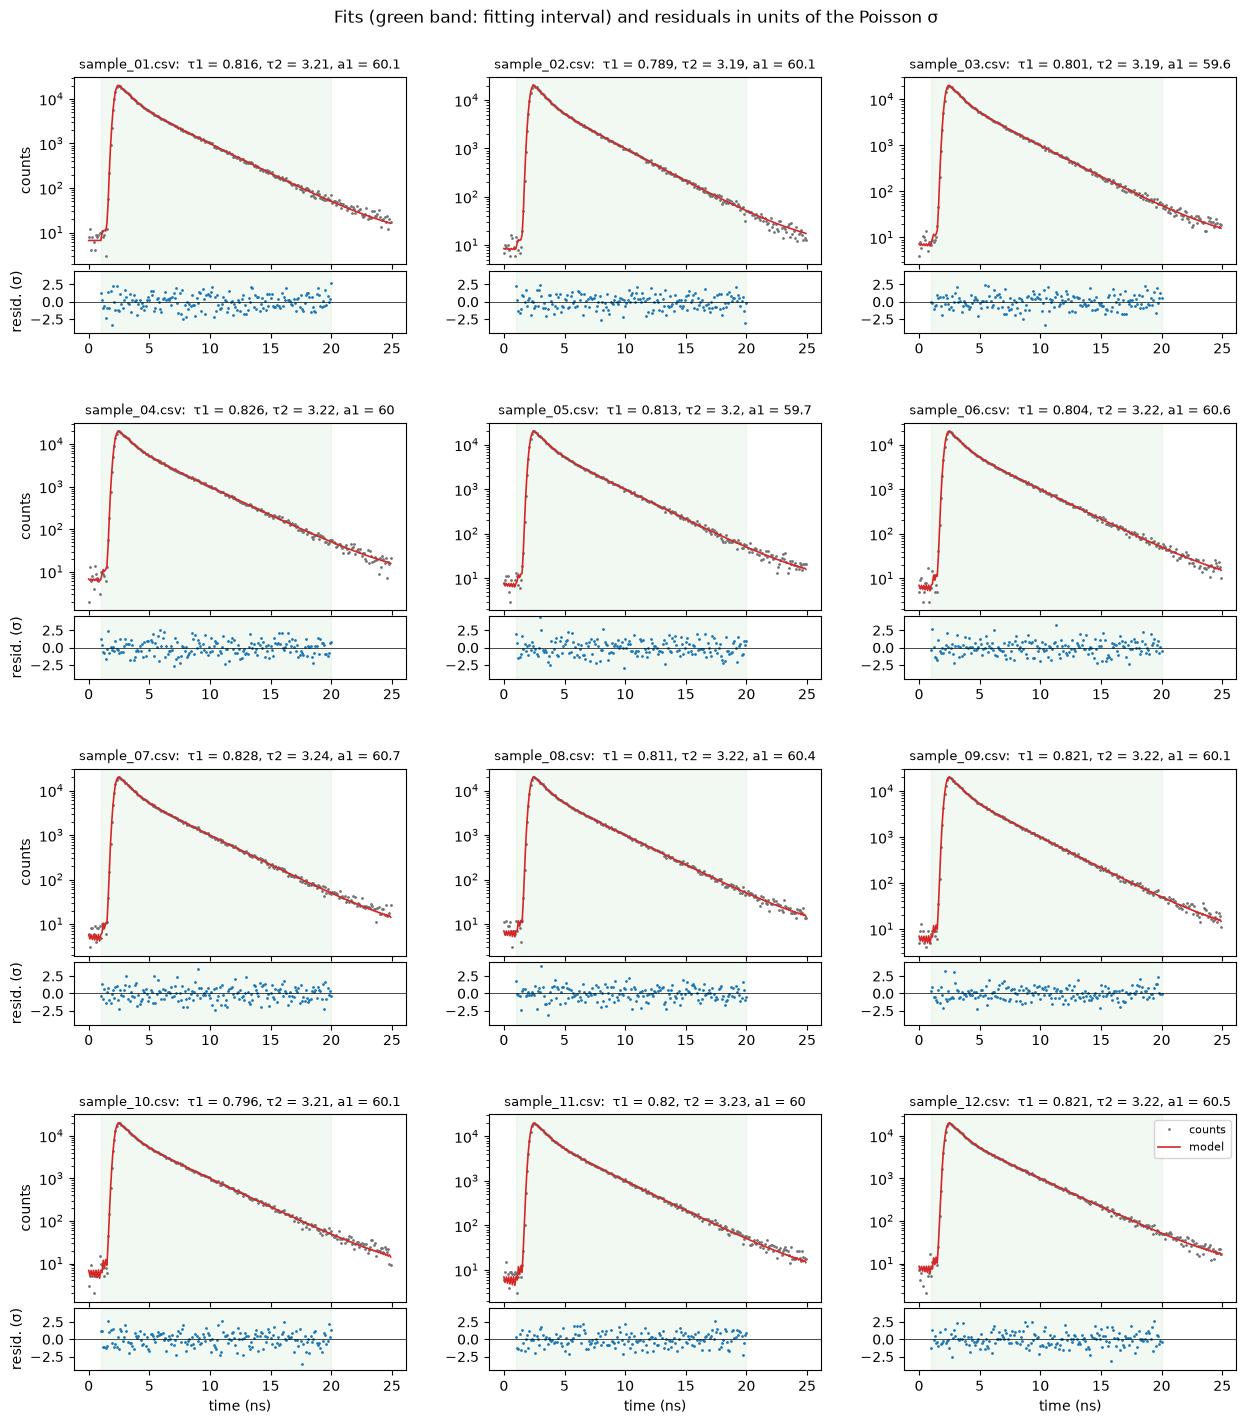

In [7]:
n_columns = 3
n_rows = int(np.ceil(len(fits) / n_columns))
fig = plt.figure(figsize=(5 * n_columns, 4.2 * n_rows))
outer = fig.add_gridspec(n_rows, n_columns, hspace=0.35, wspace=0.25)
for k, r in enumerate(fits):
    row, column = divmod(k, n_columns)
    pair = outer[row, column].subgridspec(2, 1, height_ratios=[3, 1], hspace=0.05)   # fit above residuals
    top = fig.add_subplot(pair[0])
    bottom = fig.add_subplot(pair[1], sharex=top)
    inside = r.fit_mask
    top.semilogy(r.time_ns, np.maximum(r.counts, 0.5), ".", ms=2, color="0.45", label="counts")
    top.semilogy(r.time_ns, r.model_counts, "-", lw=1.2, color="tab:red", label="model")
    bottom.plot(r.time_ns[inside], r.residuals_sigma[inside], ".", ms=2, color="tab:blue")
    for ax in (top, bottom):
        ax.axvspan(r.time_ns[inside][0], r.time_ns[inside][-1], color="tab:green", alpha=0.06)
    bottom.axhline(0, color="k", lw=0.5)
    bottom.set_ylim(-4.5, 4.5)
    top.set_title(f"{r.decay_name}:  " + ", ".join(f"{LABELS[n].split(' ')[0]} = {r.value(n):.3g}"
                                                    for n in names if n.startswith(("tau_1", "tau_2", "amplitude_1"))),
                  fontsize=9)
    top.tick_params(labelbottom=False)
    if column == 0:
        top.set_ylabel("counts")
        bottom.set_ylabel("resid. (σ)")
    if row == n_rows - 1:
        bottom.set_xlabel("time (ns)")
top.legend(fontsize=8)
fig.suptitle("Fits (green band: fitting interval) and residuals in units of the Poisson σ", y=0.92)
plt.show()

## 5 · Distribution of each free parameter

For each parameter: the values of all samples, their **mean** and **spread** (standard deviation, SD), and two typical errors for comparison:

- **mean statistical error:** if the spread is close to it, the samples differ only by photon noise; a much larger spread points to real differences between samples (or a drift).
- **mean IRF error:** the calibration's noise is common to all samples, so it shifts every value together. It does not appear in the spread, but it limits how well the *mean* is known: the mean cannot be trusted to better than about this, however many samples are averaged.

`TRUE_VALUES` marks the known truth of the example data; set it to `{}` for your own measurements.

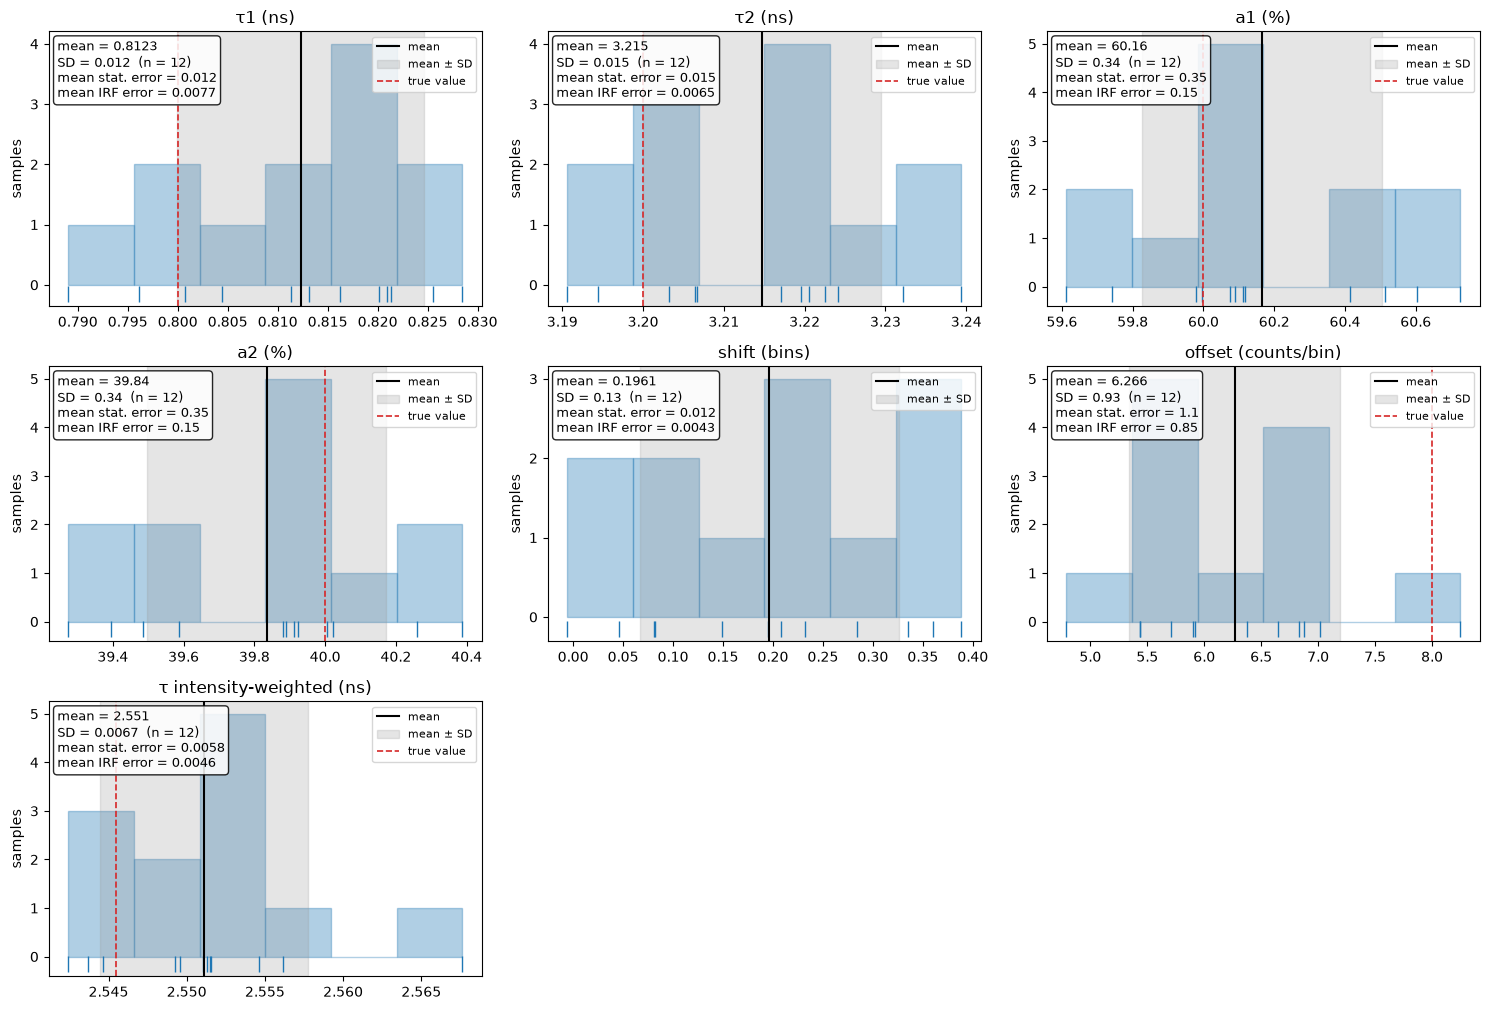

In [8]:
TRUE_VALUES = {"tau_1_ns": 0.8, "tau_2_ns": 3.2, "amplitude_1_percent": 60.0, "amplitude_2_percent": 40.0,
               "offset_counts_per_bin": 8.0, "tau_mean_intensity_ns": 2.5455}

n_columns = 3
n_rows = int(np.ceil(len(names) / n_columns))
fig, axes = plt.subplots(n_rows, n_columns, figsize=(5 * n_columns, 3.4 * n_rows), squeeze=False)
for ax, name in zip(axes.flat, names):
    values = np.array([r.value(name) for r in fits])
    errors = np.array([r.error(name) if r.error(name) is not None else np.nan for r in fits])
    irf_errors = np.array([r.irf_error(name) if r.irf_error(name) is not None else np.nan for r in fits])
    mean, spread = values.mean(), values.std(ddof=1)
    ax.hist(values, bins=min(10, max(4, len(values) // 2)), color="tab:blue", alpha=0.35, edgecolor="tab:blue")
    ax.plot(values, np.full(values.size, -0.15), "|", color="tab:blue", ms=12)          # each sample
    ax.axvline(mean, color="k", lw=1.5, label="mean")
    ax.axvspan(mean - spread, mean + spread, color="0.6", alpha=0.25, label="mean ± SD")
    if name in TRUE_VALUES:
        ax.axvline(TRUE_VALUES[name], color="tab:red", ls="--", lw=1.2, label="true value")
    ax.set_title(LABELS[name])
    ax.set_ylabel("samples")
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    ax.text(0.02, 0.97, f"mean = {mean:.4g}\nSD = {spread:.2g}  (n = {values.size})\n"
                        f"mean stat. error = {np.nanmean(errors):.2g}\nmean IRF error = {np.nanmean(irf_errors):.2g}",
            transform=ax.transAxes, va="top", fontsize=9,
            bbox=dict(boxstyle="round", facecolor="white", alpha=0.85))
    ax.legend(fontsize=8, loc="upper right")
for ax in list(axes.flat)[len(names):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

### Drift monitor

The fitted shift, in acquisition order. A trend means the timing drifted after the calibration was measured.

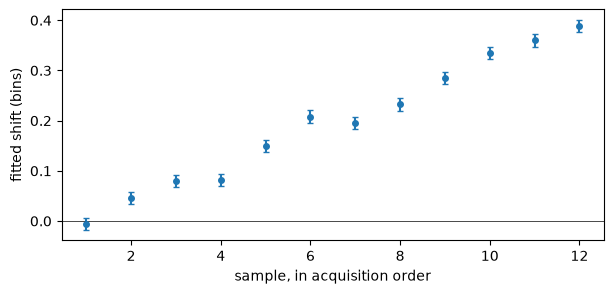

trend: +0.392 bins from first to last sample


In [9]:
shifts = np.array([r.value("shift_bins") for r in fits])
shift_errors = np.array([r.error("shift_bins") for r in fits])
fig, ax = plt.subplots(figsize=(7, 3))
ax.errorbar(np.arange(1, len(fits) + 1), shifts, yerr=shift_errors, fmt="o", ms=4, capsize=2)
ax.set(xlabel="sample, in acquisition order", ylabel="fitted shift (bins)")
ax.axhline(0, color="k", lw=0.5)
plt.show()
slope = np.polyfit(np.arange(len(fits)), shifts, 1)[0]
print(f"trend: {slope * (len(fits) - 1):+.3f} bins from first to last sample")

## Notes

- **Your own data:** change `CALIBRATION_FILES`, `SAMPLE_FILES`, `TIME_UNIT`, `MODEL` and `TRUE_VALUES`; nothing else.
- **Results for the GUI:** every result converts to JSON with `result.to_dict()`; the calibration is saved in `calibration.json`.
- **What the errors include:** the sample's photon noise (statistical) and the calibration IRF's photon noise (jackknife). Validated on 16 simulated experiments: the jackknife matches the scatter the calibration causes (e.g. τ₂: 0.0065 ns both), and the combined errors have the right scale. Not included: a wrong model.

# Part II · Measured dyes

The same steps on real measurements: three dyes in solution, measured with the same TCSPC settings (250 bins of 100 ps).
Details of the data are in `data/README.md`.

| Folder | Dye | Files | Role |
|---|---|---|---|
| `data/measured/calibration_atto655` | ATTO655, series 1 | 6 | calibration (IRF and reference lifetime) |
| `data/measured/atto655` | ATTO655, series 2 | 6 | check: the same dye, measured separately |
| `data/measured/af647_phalloidin` | Alexa Fluor 647–phalloidin | 5 | sample |
| `data/measured/star_red` | Abberior STAR RED, series 2 | 5 | sample |

There is no ground truth here. The checks are: (1) the second ATTO655 series must give the calibration dye's lifetime back;
(2) the residuals must be noise (deviance per degree of freedom ≈ 1). Where they are not, the notebook shows where the model fails.

In [10]:
MEASURED = Path("data/measured")


def read_series(folder):
    return [read_decay(path, time_unit="ns") for path in sorted((MEASURED / folder).glob("*.csv"))]


def dye_model(lifetime_bounds_ns, fit_start_ns=1.0):
    """Free lifetimes within the given (lower, upper) bounds; free shift and offset; no scatter."""
    return Model(
        n_components=len(lifetime_bounds_ns),
        lifetimes_ns=[Parameter(value=None, fixed=False, lower=lo, upper=hi) for lo, hi in lifetime_bounds_ns],
        shift_bins=Parameter(value=0.0, fixed=False, lower=-3.0, upper=3.0),
        scatter=Parameter(value=0.0, fixed=True),
        offset=Parameter(value=None, fixed=False),
        fit_start_ns=fit_start_ns,
        fit_end_ns=20,
    )


def fit_series(decays, model):
    results = run_batch(decays, measured_calibration, model)
    for failure in (r for r in results if not isinstance(r, SampleResult)):
        print(f"FAILED {failure.decay_name}: {failure.error_message}")
    return [r for r in results if isinstance(r, SampleResult)]


def series_summary(fits):
    """Mean ± SD over the series of every lifetime and amplitude, and the mean deviance per dof."""
    n = fits[0].model["n_components"]
    names = [f"tau_{i + 1}_ns" for i in range(n)] + ([f"amplitude_{i + 1}_percent" for i in range(n)] if n > 1 else [])
    names += ["shift_bins"]
    parts = []
    for name in names:
        values = np.array([r.value(name) for r in fits])
        parts.append(f"{LABELS[name].split(' ')[0]} = {values.mean():.3f} ± {values.std(ddof=1):.3f}")
    deviance = np.mean([r.deviance_per_dof for r in fits])
    return ", ".join(parts) + f";  dev/dof = {deviance:.2f}"


def rms_residual_by_time(result, edges_ns=(1, 3, 6, 12, 20)):
    """RMS of the residuals (in σ) in time windows: 1 means noise, more means the model misses something there."""
    t, z, inside = result.time_ns, result.residuals_sigma, result.fit_mask
    out = {}
    for a, b in zip(edges_ns[:-1], edges_ns[1:]):
        window = inside & (t >= a) & (t < b)
        out[f"{a}-{b} ns"] = float(np.sqrt(np.mean(z[window] ** 2))) if window.any() else np.nan
    return out


def plot_fits_by_model(fits_by_model, title):
    """For each model: the first decay with its fit (top) and the residuals of every decay of the series (bottom)."""
    fig, axes = plt.subplots(2, len(fits_by_model), figsize=(5 * len(fits_by_model), 5.5),
                             sharex=True, gridspec_kw=dict(height_ratios=[3, 2], hspace=0.05), squeeze=False)
    for column, (label, fits) in enumerate(fits_by_model.items()):
        top, bottom = axes[0, column], axes[1, column]
        r = fits[0]
        top.semilogy(r.time_ns, np.maximum(r.counts, 0.5), ".", ms=2, color="0.45", label="counts")
        top.semilogy(r.time_ns, r.model_counts, "-", lw=1.2, color="tab:red", label="model")
        top.set_title(f"{label}\nmean dev/dof = {np.mean([f.deviance_per_dof for f in fits]):.2f}", fontsize=10)
        for f in fits:
            bottom.plot(f.time_ns[f.fit_mask], f.residuals_sigma[f.fit_mask], "-", lw=0.6, alpha=0.7)
        for ax in (top, bottom):
            ax.axvspan(r.time_ns[r.fit_mask][0], r.time_ns[r.fit_mask][-1], color="tab:green", alpha=0.06)
        bottom.axhline(0, color="k", lw=0.5)
        bottom.set_ylim(-12, 12)
        bottom.set_xlabel("time (ns)")
        if column == 0:
            top.set_ylabel("counts")
            bottom.set_ylabel("resid. (σ), all files")
            top.legend(fontsize=8)
    fig.suptitle(title, y=0.99)
    plt.show()

## 6 · Calibration on ATTO655 (series 1)

ATTO655 in solution is monoexponential and emits in the same channel as the other two dyes, so it is the calibration dye.
The library sums the repetitions that pass the shape test and extracts the IRF from the sum.

N = 6 repetitions; summed: 5
EXCLUDED Decay_ATTO655 Series 1 for IRF_06.csv: shape test log10 p = -4.6
shape-test p-values: {'06': '2.4e-05', '01': '0.76', '02': '0.028', '03': '0.018', '04': '0.16', '05': '0.37'}
IRF: λ = 0.0132 bins⁴, cut m = 19, chosen by: cross_validated
ATTO655 lifetime (blind, from the calibration): 1.8853 ± 0.0007 ns


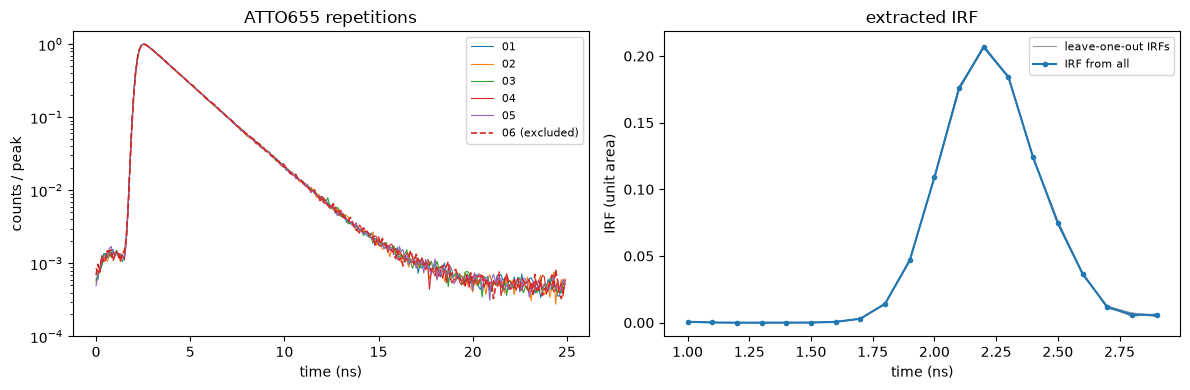

In [11]:
measured_calibration_decays = read_series("calibration_atto655")
measured_calibration = build_calibration(measured_calibration_decays)
c = measured_calibration

print(f"N = {c.n_repetitions} repetitions; summed: {len(c.accepted)}")
for item in c.excluded:
    print(f"EXCLUDED {item['name']}: shape test log10 p = {item['log10_p_value']:.1f}")
print("shape-test p-values:", {name[-6:-4]: f"{p:.2g}" for name, p in c.shape_test_p_values.items()})
print(f"IRF: λ = {c.best_lambda_bins4:.3g} bins⁴, cut m = {c.best_m_bin}, chosen by: {c.selection}")
print(f"ATTO655 lifetime (blind, from the calibration): {c.tau_reference_ns:.4f} ± {c.tau_reference_error_ns:.4f} ns")

fig, (ax_reps, ax_irf) = plt.subplots(1, 2, figsize=(12, 4))
excluded_names = [item["name"] for item in c.excluded]
for decay in measured_calibration_decays:
    is_excluded = decay.name in excluded_names
    ax_reps.semilogy(decay.time_ns, decay.counts / decay.counts.max(), "--" if is_excluded else "-",
                     color="tab:red" if is_excluded else None, lw=1.2 if is_excluded else 0.8,
                     label=decay.name[-6:-4] + (" (excluded)" if is_excluded else ""))
ax_reps.set(xlabel="time (ns)", ylabel="counts / peak", title="ATTO655 repetitions", ylim=(1e-4, 1.5))
ax_reps.legend(fontsize=8)
irf_time = c.time_ns[c.irf_start_bin:c.irf_start_bin + c.irf.size]
for k, irf_k in enumerate(c.jackknife_irfs):
    ax_irf.plot(irf_time, irf_k, "-", lw=0.8, color="0.6", label="leave-one-out IRFs" if k == 0 else None)
ax_irf.plot(irf_time, c.irf, "o-", ms=3, color="tab:blue", label="IRF from all")
ax_irf.set(xlabel="time (ns)", ylabel="IRF (unit area)", title="extracted IRF")
ax_irf.legend(fontsize=8)
plt.tight_layout()
plt.show()

The shape test rejects one repetition. Its p-value is small but not extreme (compare the simulated
intruder in Part I, a different dye, at log10 p ≈ −80). On real data this usually means a small change during that
acquisition (count rate, focus, timing) rather than a different sample; the IRF from the remaining five is unaffected
in practice, as the leave-one-out IRFs show.

## 7 · Check: ATTO655, series 2

An independent series of the same dye, fitted with one component. Its lifetime must agree with the calibration's.

file                τ (ns)   τ / τ_calibration − 1   shift (bins)  dev/dof
01          1.8815 ± 0.0020                 -0.20 %          0.023     1.07
02          1.8816 ± 0.0020                 -0.20 %          0.022     1.52
03          1.8836 ± 0.0020                 -0.09 %         -0.025     1.03
04          1.8829 ± 0.0020                 -0.13 %          0.001     1.32
05          1.8836 ± 0.0020                 -0.09 %         -0.010     1.41
06          1.8806 ± 0.0020                 -0.25 %          0.014     1.24
series: τ1 = 1.882 ± 0.001, shift = 0.004 ± 0.019;  dev/dof = 1.27


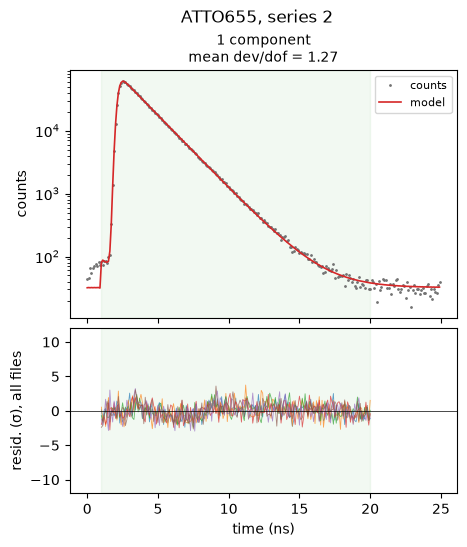

In [12]:
atto_fits = fit_series(read_series("atto655"), dye_model([(0.1, 10.0)]))

print(f"{'file':6s}{'τ (ns)':>20s}{'τ / τ_calibration − 1':>24s}{'shift (bins)':>15s}{'dev/dof':>9s}")
for r in atto_fits:
    error = r.total_error("tau_1_ns") or r.error("tau_1_ns")
    print(f"{r.decay_name[-6:-4]:6s}{r.value('tau_1_ns'):12.4f} ± {error:.4f}"
          f"{100 * (r.value('tau_1_ns') / c.tau_reference_ns - 1):+22.2f} %"
          f"{r.value('shift_bins'):15.3f}{r.deviance_per_dof:9.2f}")
print("series:", series_summary(atto_fits))
plot_fits_by_model({"1 component": atto_fits}, "ATTO655, series 2")

Series 2 gives the calibration lifetime back to within a few tenths of a percent, with residuals close to noise.
This is the end-to-end check of the IRF on real data (it is also a regression test: `tests/test_measured_dyes.py`).

## 8 · Alexa Fluor 647–phalloidin

Free Alexa Fluor 647 has a lifetime near 1 ns; bound to phalloidin it need not be monoexponential.
Fit 1, 2 and 3 components and compare the residuals.

peak counts: AF647 6.83e+05, calibration 6.09e+04


1 component: τ1 = 1.145 ± 0.000, shift = -0.105 ± 0.019;  dev/dof = 321.74
    RMS residual (σ) by time window, first file: {'1-3 ns': 27.7, '3-6 ns': 22.9, '6-12 ns': 21.9, '12-20 ns': 6.8}
2 components: τ1 = 0.753 ± 0.002, τ2 = 1.492 ± 0.002, a1 = 63.500 ± 0.271, a2 = 36.500 ± 0.271, shift = 0.084 ± 0.019;  dev/dof = 8.77
    RMS residual (σ) by time window, first file: {'1-3 ns': 5.3, '3-6 ns': 2.7, '6-12 ns': 3.3, '12-20 ns': 1.2}
3 components: τ1 = 0.600 ± 0.000, τ2 = 1.104 ± 0.016, τ3 = 1.737 ± 0.035, a1 = 35.510 ± 0.515, a2 = 50.657 ± 1.243, a3 = 13.833 ± 1.696, shift = 0.097 ± 0.019;  dev/dof = 6.92
    RMS residual (σ) by time window, first file: {'1-3 ns': 4.6, '3-6 ns': 1.7, '6-12 ns': 3.1, '12-20 ns': 1.4}


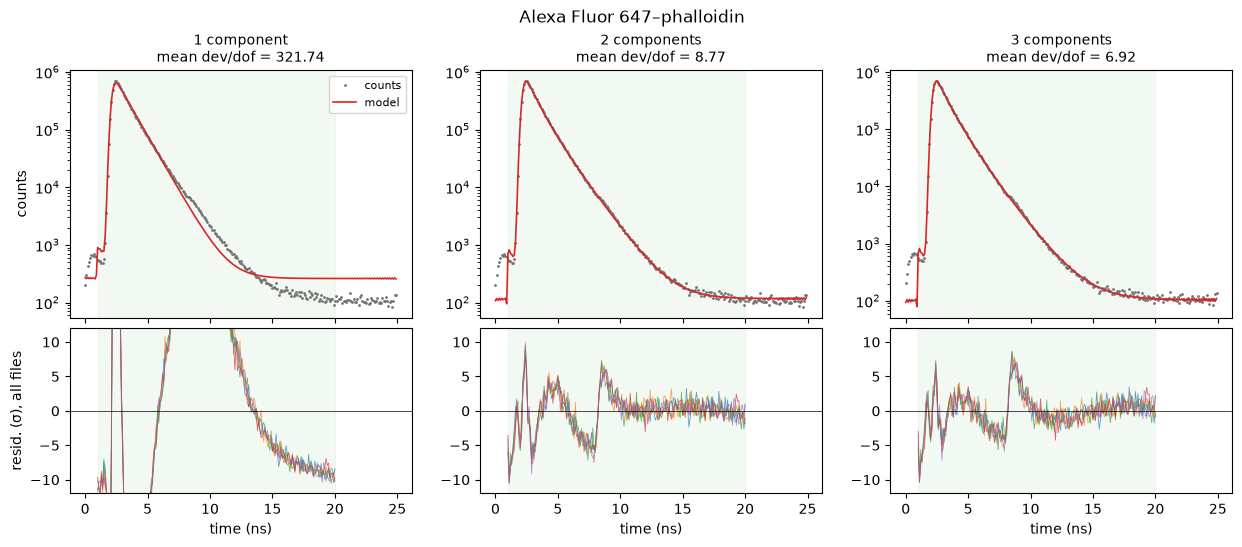

In [13]:
af_decays = read_series("af647_phalloidin")
print(f"peak counts: AF647 {np.mean([d.counts.max() for d in af_decays]):.3g}, "
      f"calibration {np.mean([d.counts.max() for d in measured_calibration_decays]):.3g}")

af_models = {
    "1 component": dye_model([(0.1, 10.0)]),
    "2 components": dye_model([(0.1, 1.0), (1.0, 10.0)]),
    "3 components": dye_model([(0.05, 0.6), (0.6, 1.5), (1.5, 10.0)]),
}
af_fits = {label: fit_series(af_decays, model) for label, model in af_models.items()}
for label, fits in af_fits.items():
    print(f"{label}: {series_summary(fits)}")
    print("    RMS residual (σ) by time window, first file:",
          {k: round(v, 1) for k, v in rms_residual_by_time(fits[0]).items()})
plot_fits_by_model(af_fits, "Alexa Fluor 647–phalloidin")

**Reading the result.** One component is clearly wrong. Two and three components lower the deviance, but neither brings
it near 1: the residuals keep a sharp step at about 8.3 ns, some 6 ns after the peak, in every file and every model.
A feature that sharp, at a fixed delay, cannot come from a sum of exponentials; it looks like a small secondary peak of
the instrument response (a reflection or detector afterpulse). These decays have about ten times the counts of the
calibration, so an IRF feature too small to be resolved in the calibration becomes significant here; count-rate effects
(pile-up) at this intensity are a second suspect. With three components the shortest lifetime also sits at its bound
(0.6 ns), another sign that the extra component is absorbing a mismatch rather than describing the dye.
The lifetimes therefore depend on the model chosen; to settle it, measure the calibration at a comparable count rate,
or attenuate the sample.

## 9 · Abberior STAR RED

Fit one component over the full window, then starting after the rise (2.5 ns).

1 component, from 1.0 ns: τ1 = 3.638 ± 0.002, shift = -0.641 ± 0.019;  dev/dof = 4.70
1 component, from 2.5 ns: τ1 = 3.665 ± 0.003, shift = -0.379 ± 0.018;  dev/dof = 1.13
counts before the rise (0–0.5 ns): 620;  at the end of the window: 612;  window 25 ns, τ ≈ 3.67 ns


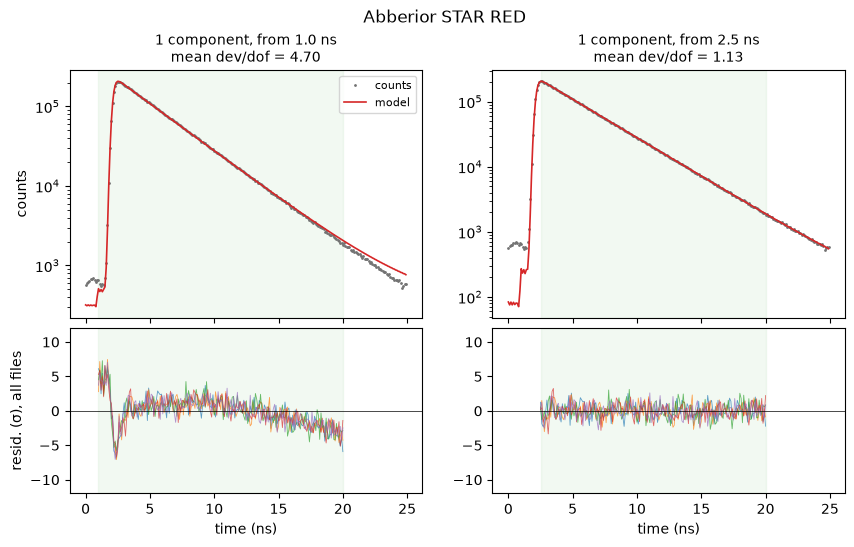

In [14]:
sr_decays = read_series("star_red")
sr_fits = {
    "1 component, from 1.0 ns": fit_series(sr_decays, dye_model([(0.1, 10.0)])),
    "1 component, from 2.5 ns": fit_series(sr_decays, dye_model([(0.1, 10.0)], fit_start_ns=2.5)),
}
for label, fits in sr_fits.items():
    print(f"{label}: {series_summary(fits)}")

first = sr_decays[0]
print(f"counts before the rise (0–0.5 ns): {first.counts[:5].mean():.0f};  at the end of the window: "
      f"{first.counts[-10:].mean():.0f};  window {first.time_ns[-1] + first.bin_width_ns:.0f} ns, "
      f"τ ≈ {sr_fits['1 component, from 2.5 ns'][0].value('tau_1_ns'):.2f} ns")
plot_fits_by_model(sr_fits, "Abberior STAR RED")

**Reading the result.** Over the full window the fit misses the rise, and the fitted shift is large (−0.6 bins).
Starting after the rise, the residuals are noise and the lifetime changes by less than 1 % (the shift, now poorly
constrained, stays near −0.4 bins). The counts before the rise are far above the fitted offset and as high as at the
end of the window: with τ ≈ 3.7 ns in a 25 ns window, the decay from the
previous pulse is not over when the next one arrives (an *incomplete decay*). The model of version 1 has only a flat
offset for this, so it cannot fit the rise. The incomplete-decay model is planned for version 2; until then, start the
fit after the rise for long lifetimes.

## 10 · Summary

The model used for each dye; fill in `LITERATURE_TAU_NS` with reference values from your own sources to compare.

In [15]:
LITERATURE_TAU_NS = {"ATTO655": None, "AF647–phalloidin": None, "STAR RED": None}   # fill in, in ns

chosen = {
    "ATTO655": atto_fits,
    "AF647–phalloidin": af_fits["2 components"],
    "STAR RED": sr_fits["1 component, from 2.5 ns"],
}
print(f"calibration (ATTO655, series 1): τ = {c.tau_reference_ns:.3f} ± {c.tau_reference_error_ns:.3f} ns\n")
for dye, fits in chosen.items():
    n = fits[0].model["n_components"]
    tau = "tau_mean_intensity_ns" if n > 1 else "tau_1_ns"
    values = np.array([r.value(tau) for r in fits])
    literature = LITERATURE_TAU_NS[dye]
    print(f"{dye:18s} {n} comp.  τ{'(intensity-weighted)' if n > 1 else ''} = {values.mean():.3f} ± "
          f"{values.std(ddof=1):.3f} ns (SD over {len(fits)} files), dev/dof = "
          f"{np.mean([r.deviance_per_dof for r in fits]):.2f}"
          + (f", literature {literature} ns" if literature is not None else ""))

calibration (ATTO655, series 1): τ = 1.885 ± 0.001 ns

ATTO655            1 comp.  τ = 1.882 ± 0.001 ns (SD over 6 files), dev/dof = 1.27
AF647–phalloidin   2 comp.  τ(intensity-weighted) = 1.146 ± 0.000 ns (SD over 5 files), dev/dof = 8.77
STAR RED           1 comp.  τ = 3.665 ± 0.003 ns (SD over 5 files), dev/dof = 1.13
